In [4]:
%pip install mlxtend

Note: you may need to restart the kernel to use updated packages.


# Lab01: Regression
##  1.1 Linear Regression
### Khai báo sử dụng thư

In [5]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder , PolynomialFeatures
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from mlxtend.plotting import  scatterplotmatrix , heatmap
import seaborn as sns
from sklearn.model_selection import train_test_split , GridSearchCV
from sklearn.metrics import mean_absolute_error , mean_squared_error , r2_score 
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor , AdaBoostRegressor ,HistGradientBoostingRegressor

In [6]:
df = pd.read_csv('AmesHousing.txt',sep='\t')
df.head()

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [7]:
cols = ['Overall Qual', 'Overall Cond', 'Gr Liv Area',
'Central Air', 'Total Bsmt SF', 'SalePrice']
df = pd.read_csv('AmesHousing.txt', usecols = cols , sep='\t')
df.head()

,Overall Qual,Overall Cond,Total Bsmt SF,Central Air,Gr Liv Area,SalePrice
0,6,5,1080.0,Y,1656,215000
1,5,6,882.0,Y,896,105000
2,6,6,1329.0,Y,1329,172000
3,7,5,2110.0,Y,2110,244000
4,5,5,928.0,Y,1629,189900


# 1.2 preprocessing

In [8]:
encoder = LabelEncoder()
df['Central Air'] = encoder.fit_transform(df['Central Air'])

In [9]:
df.head()

,Overall Qual,Overall Cond,Total Bsmt SF,Central Air,Gr Liv Area,SalePrice
0,6,5,1080.0,1,1656,215000
1,5,6,882.0,1,896,105000
2,6,6,1329.0,1,1329,172000
3,7,5,2110.0,1,2110,244000
4,5,5,928.0,1,1629,189900


In [10]:
df.isna().sum()

Overall Qual     0
Overall Cond     0
Total Bsmt SF    1
Central Air      0
Gr Liv Area      0
SalePrice        0
dtype: int64

In [11]:
df.dropna(axis = 0 , inplace = True)

In [12]:
df.isna().sum()

Overall Qual     0
Overall Cond     0
Total Bsmt SF    0
Central Air      0
Gr Liv Area      0
SalePrice        0
dtype: int64

# 1.3 Correlation (Hệ số tương quan)

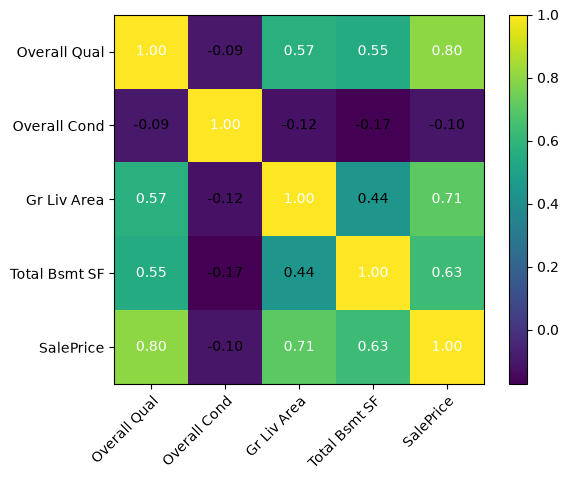

In [13]:
cols_con = ['Overall Qual', 'Overall Cond', 'Gr Liv Area', 'Total Bsmt SF', 'SalePrice']

heatmap(df[cols_con].corr().values, row_names=cols_con, column_names=cols_con)
plt.show()

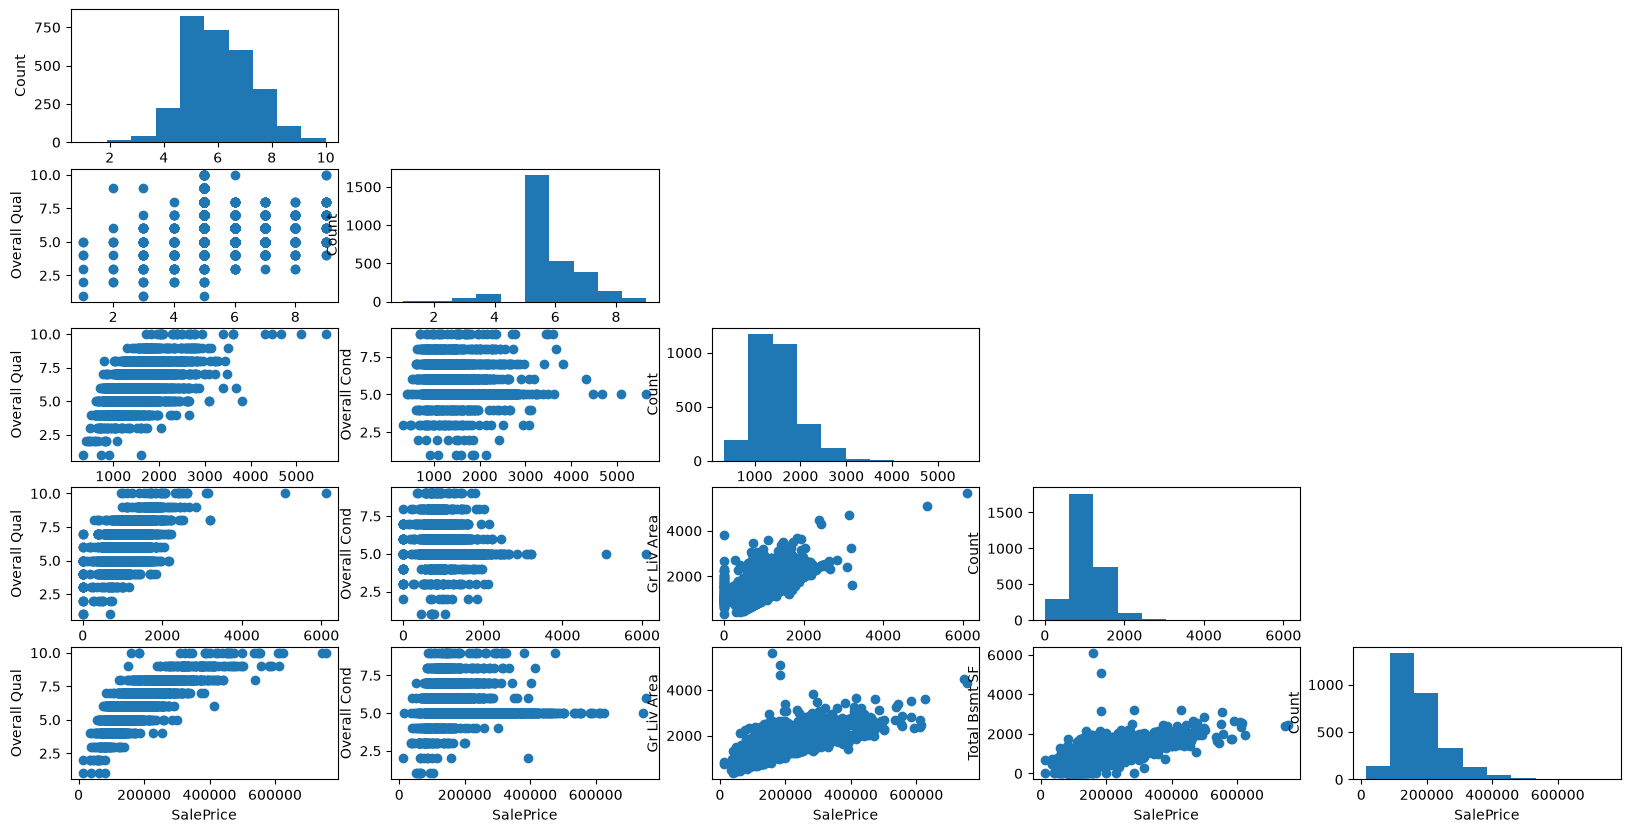

In [14]:
scatterplotmatrix(df[cols_con].values, names = cols_con , figsize=(20 ,10) )
plt.show()

# 1.4 Build model


In [15]:
X = df.drop(columns = 'SalePrice')
y = df['SalePrice']
X_train,X_test , y_train , y_test = train_test_split(X,y)
X_train.shape ,X_test.shape , y_train.shape , y_test.shape 


((2196, 5), (733, 5), (2196,), (733,))

In [16]:
lg = LinearRegression()
lg.fit(X_train ,y_train)
lg.score(X_train ,y_train) , lg.score(X_test ,y_test)

(0.7577040840549457, 0.781664574459995)

# 1.5 Feature importances

In [17]:
df_imp = pd.DataFrame({
    'importances':lg.coef_,
    'features':lg.feature_names_in_
}).sort_values(by='importances')
df_imp

,importances,features
2,34.629893,Total Bsmt SF
4,50.069153,Gr Liv Area
1,867.239448,Overall Cond
3,13065.624874,Central Air
0,27511.935787,Overall Qual


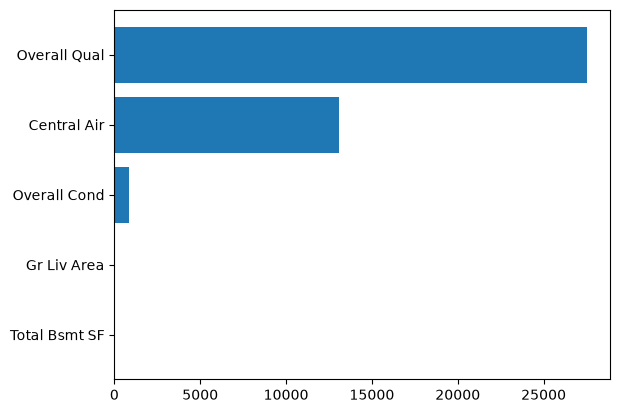

In [18]:
plt.barh(y=df_imp['features'], width=df_imp['importances'])
plt.show()

# Linear Regression with Polynomial

In [19]:
pf = PolynomialFeatures(degree=2)
X_train_pf = pf.fit_transform(X_train)
X_test_pf = pf.transform(X_test)

In [20]:
lg = LinearRegression()
lg.fit(X_train_pf ,y_train)
lg.score(X_train_pf ,y_train) , lg.score(X_test_pf ,y_test)

(0.8476597935936944, 0.8497348887313771)

In [21]:
dt = DecisionTreeRegressor()
dt.fit(X_train ,y_train)
dt.score(X_train ,y_train) , dt.score(X_test ,y_test)

(0.9953526319566304, 0.7685362655780033)

In [22]:
grid = GridSearchCV(estimator=dt,param_grid={
    'max_depth':[5,6,7],
    'min_samples_split':[2,3,4],
    'min_samples_leaf':[1,2,3,4]
})
grid.fit(X_train,y_train)
grid.best_score_,grid.best_params_

(np.float64(0.8128647019306946),
 {'max_depth': 6, 'min_samples_leaf': 3, 'min_samples_split': 3})

In [23]:
dt = DecisionTreeRegressor(max_depth=6 , min_samples_split= 4 ,min_samples_leaf=3 )
dt.fit(X_train ,y_train)
dt.score(X_train ,y_train) , dt.score(X_test ,y_test)

(0.876541565605603, 0.822552191288175)

In [24]:
rf = RandomForestRegressor()
rf.fit(X_train ,y_train)
rf.score(X_train ,y_train) , rf.score(X_test ,y_test)

(0.9736123440158813, 0.8531208630449779)

In [25]:
grid = GridSearchCV(estimator=rf,param_grid={
    'max_depth':[7,8,9],
    'min_samples_split':[2,3],
    'min_samples_leaf':[1,2,3,4]
})
grid.fit(X_train,y_train)
grid.best_score_,grid.best_params_

(np.float64(0.841531284323467),
 {'max_depth': 8, 'min_samples_leaf': 2, 'min_samples_split': 2})

In [26]:
dt = DecisionTreeRegressor(max_depth=8 , min_samples_split= 2 ,min_samples_leaf=2 )
dt.fit(X_train ,y_train)
dt.score(X_train ,y_train) , dt.score(X_test ,y_test)

(0.9139355356723896, 0.8357429063849523)

In [27]:
adaboost = AdaBoostRegressor()
adaboost.fit(X_train ,y_train)
adaboost.score(X_train ,y_train) , adaboost.score(X_test ,y_test)

(0.8240018393612734, 0.7790508719538977)

In [29]:
hist = HistGradientBoostingRegressor()
hist.fit(X_train ,y_train)
hist.score(X_train ,y_train) , hist.score(X_test ,y_test)

(0.9032081164040945, 0.8389555877860654)

In [30]:
df_imp = pd.DataFrame({
    'features': rf.feature_names_in_,
    'importances':rf.feature_importances_
}).sort_values(by='importances')
df_imp

,features,importances
3,Central Air,0.006127
1,Overall Cond,0.018955
2,Total Bsmt SF,0.121430
4,Gr Liv Area,0.203025
0,Overall Qual,0.650462


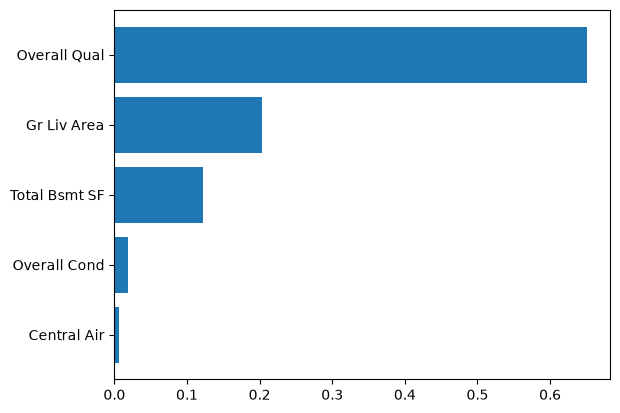

In [31]:
plt.barh(y = df_imp['features'], width= df_imp['importances'])
plt.show()

# 1.6 Validation


In [32]:
y_test_pred = rf.predict(X_test)
data_validation = []
data_validation.append({
    'model':'RandomForest',
    'mean_absolute_error': mean_squared_error(y_test,y_test_pred),
    'mean_squared_error':mean_squared_error(y_test,y_test_pred)
})
y_test_pred = dt.predict(X_test)
data_validation.append({
    'model':'DecisionTree',
    'mean_absolute_error': mean_squared_error(y_test,y_test_pred),
    'mean_squared_error':mean_squared_error(y_test,y_test_pred)
})
y_test_pred = adaboost.predict(X_test)
data_validation.append({
    'model':'AdaBoost',
    'mean_absolute_error': mean_squared_error(y_test,y_test_pred),
    'mean_squared_error':mean_squared_error(y_test,y_test_pred)
})
y_test_pred = hist.predict(X_test)
data_validation.append({
    'model':'HistGradientBoosting',
    'mean_absolute_error': mean_squared_error(y_test,y_test_pred),
    'mean_squared_error':mean_squared_error(y_test,y_test_pred)
})
df_validation = pd.DataFrame(data_validation)
df_validation

,model,mean_absolute_error,mean_squared_error
0,RandomForest,9.767225e+08,9.767225e+08
1,DecisionTree,1.092283e+09,1.092283e+09
2,AdaBoost,1.469276e+09,1.469276e+09
3,HistGradientBoosting,1.070919e+09,1.070919e+09
